In [28]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn import set_config
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [29]:
train = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")
test = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")
gender_submission = pd.read_csv("/kaggle/input/competitions/titanic/gender_submission.csv")
pd.set_option("display.max_columns", None)

In [30]:
train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [31]:
# For Train DataSet
train_y = train.Survived 
train_x = train.drop(["PassengerId","Survived","Name","Ticket","Cabin"],axis = 1)

train_x.Sex = train_x.Sex.map({"male": 1, "female": 0})
train_x.Pclass = train_x.Pclass.map({3:"Lower_Class", 2:"Middle_Class", 1:"Upper_Class"})

ohe_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
).fit(train_x[["Pclass", "Embarked"]])

set_config(transform_output="pandas")

train_encoded = ohe_encoder.transform(train_x[["Pclass", "Embarked"]])
train_x = train_x.join(train_encoded[['Pclass_Lower_Class', 'Pclass_Upper_Class',
       'Embarked_C', 'Embarked_Q']])

train_x.Pclass = train_x.Pclass.map({"Lower_Class":0, "Middle_Class":1, "Upper_Class":2})
train_x.drop(["Embarked"],axis=1,inplace=True)


In [32]:
#For Test DataSet
test_id = test.PassengerId
test_x = test.drop(["PassengerId","Name","Ticket","Cabin"],axis = 1)
test_x.Sex = test.Sex.map({"male": 1, "female": 0})
test_x.Pclass = test_x.Pclass.map({3:"Lower_Class", 2:"Middle_Class", 1:"Upper_Class"})

In [33]:
train_x.dropna(inplace=True)
train_y = train_y.loc[train_x.index]

In [34]:
X_train, X_test, y_train, y_test = train_test_split(train_x, train_y, test_size=0.2, random_state = 42)

decisiontree = DecisionTreeClassifier(random_state = 42)
decisiontree.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

              precision    recall  f1-score   support

           0       0.79      0.78      0.78        89
           1       0.64      0.67      0.65        54

    accuracy                           0.73       143
   macro avg       0.72      0.72      0.72       143
weighted avg       0.74      0.73      0.74       143



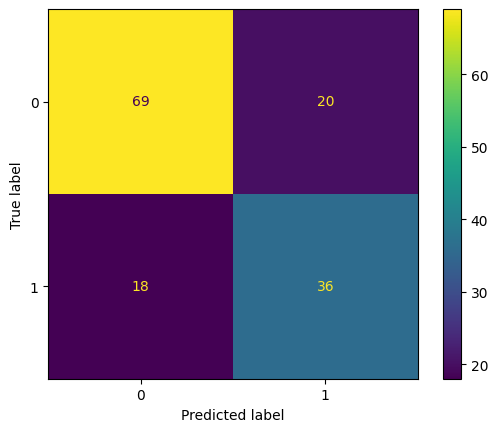

In [35]:
prediction = decisiontree.predict(X_test)
print(classification_report(prediction,y_test))
cm = confusion_matrix(prediction,y_test)
confusion_matrix_plot = ConfusionMatrixDisplay(confusion_matrix=cm, 
                      display_labels=decisiontree.classes_ )
confusion_matrix_plot.plot()
plt.show()

In [36]:
imputer = KNNImputer(n_neighbors=5)
imputer.fit(train_x[["Age","Fare"]])
test_x[["Age","Fare"]] = imputer.transform(test_x[["Age","Fare"]])


In [37]:
test_encoded = ohe_encoder.transform(test_x[["Pclass", "Embarked"]])
test_x = test_x.join(test_encoded[['Pclass_Lower_Class', 'Pclass_Upper_Class',
                                    'Embarked_C', 'Embarked_Q']])

test_x.Pclass = test_x.Pclass.map({"Lower_Class":0, "Middle_Class":1, "Upper_Class":2})
test_x.drop(["Embarked"],axis=1,inplace=True)

In [38]:
decisiontree.fit(train_x,train_y)
prediction = decisiontree.predict(test_x)

In [39]:
pred_df = pd.DataFrame({
    "PassengerId": test_id.to_numpy(),
    "Survived": prediction
})

pred_df.to_csv("/kaggle/working/submission.csv", index=False)